**Live deployment:** Pending. Replace this line with the verified Hugging Face Space URL before submitting.

# PixelDetective
AIC354 Machine Learning Fundamentals · COMSATS University Islamabad, Lahore Campus

**Presented by** Saad Faisal  
**Instructor** Dr. Rao Muhammad Adeel Nawab

## 1. Experimental design
Classify CASIA v2 photographs as Authentic or Manipulated. Extract fixed features with [EfficientNet-B0](https://huggingface.co/google/efficientnet-b0) (pooled features) and [ViT-Tiny](https://huggingface.co/WinKawaks/vit-tiny-patch16-224) (CLS token). The expanded comparison adds [DINOv2 Base](https://huggingface.co/facebook/dinov2-base) (CLS token) and [ConvNeXt V2 Tiny](https://huggingface.co/facebook/convnextv2-tiny-22k-224) (pooled features). Fit a standardized logistic regression head per encoder. Use the original project’s group-aware split. Matching decoded pixels, known source IDs, and matching nonconstant coarse thumbnail fingerprints stay together. Oversized connected groups stay in training. Choose regularization and the preferred model using validation macro F1. Report all four systems on the same held-out test images.

The inputs are 128 × 128 RGB except DINOv2, which uses 126 × 126 to match its 14-pixel patch grid. ConvNeXt V2 applies its checkpoint’s resize and center crop at the target size.

## 2. Stage the project
In Colab, select a GPU runtime. Upload the project ZIP through the prompt below. You can also place it at /content/PixelDetective-Expanded.zip before running the cell. Local users can start Jupyter from the extracted PixelDetective folder.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import os
import sys

if not Path("train.py").is_file():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError("Start Jupyter from the extracted PixelDetective folder.") from exc

    archive = Path("/content/PixelDetective-Expanded.zip")
    if not archive.is_file():
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
        if len(zip_names) != 1:
            raise ValueError("Choose exactly one PixelDetective project ZIP.")
        archive = Path(zip_names[0])
    with ZipFile(archive) as bundle:
        if "PixelDetective/train.py" not in bundle.namelist():
            raise ValueError("Choose the PixelDetective project ZIP.")
        bundle.extractall("/content/pixel_project")
    os.chdir("/content/pixel_project/PixelDetective")
sys.path.insert(0, str(Path.cwd()))
print(Path.cwd())

/workspace/scratch/d3b66affdbe4/PixelDetective


In [ ]:
%pip install -q -r requirements-train.txt

## 3. Get CASIA v2
This cell downloads the full Kaggle release. If Kaggle requires sign-in, download the ZIP manually, extract it, and set DATA to the parent of Au/ and Tp/. Keep the original dataset ZIP for course submission.

In [3]:
DOWNLOAD_DATA = False  # Switch on to fetch data for training or held-out examples.
DATA = None  # Or set to Path('/content/extracted_casia').
if DOWNLOAD_DATA:
    import kagglehub
    DATA = Path(kagglehub.dataset_download("divg07/casia-20-image-tampering-detection-dataset/versions/1"))
if DATA is not None:
    print(DATA)
else:
    print("Using the bundled evaluation results.")

Using the bundled evaluation results.


## 4. Fit and compare
Use all readable CASIA class images across the three partitions. The scaler and head see only training labels during fitting. The notebook exports the test metrics, both heads, split membership and unreadable-file log. If GPU memory is limited, use a batch size of 16 or 8.

The package includes the recorded benchmark outputs. Set RUN_TRAINING to True to reproduce them. The bundled results load without downloading the dataset.

In [4]:
import json

OUT = Path("artifacts")
RUN_TRAINING = False
if RUN_TRAINING:
    from train import run
    if DATA is None:
        raise ValueError("Set DOWNLOAD_DATA to True or point DATA at extracted CASIA before training.")
    metrics = run(DATA, OUT, batch_size=32)
else:
    metrics = json.loads((OUT / "metrics.json").read_text())
print(json.dumps(metrics["audit"], indent=2))

{
  "class_counts": {
    "train": {
      "0": 4235,
      "1": 4135
    },
    "test": {
      "0": 1628,
      "1": 494
    },
    "validation": {
      "0": 1628,
      "1": 494
    }
  },
  "known_source_groups": 6258,
  "largest_group": 4124,
  "images_without_parsed_source_id": 0,
  "unreadable_images": 0,
  "files_by_class_and_extension": {
    "0": {
      ".jpg": 7437,
      ".bmp": 54
    },
    "1": {
      ".tif": 3059,
      ".jpg": 2064
    }
  }
}


## 5. Inspect held-out results
Confusion matrix rows are ground truth and columns are predictions. The baseline always predicts the most frequent training label.

,Accuracy,Macro F1,JPEG-only macro F1,Manipulated precision,Manipulated recall
EfficientNet-B0,0.703110,0.613446,0.527908,0.387789,0.475709
ViT-Tiny,0.725259,0.661832,0.528168,0.437236,0.627530
DINOv2 Base,0.725259,0.636405,0.540970,0.423143,0.495951
ConvNeXt V2 Tiny,0.738926,0.671034,0.556651,0.454819,0.611336
Majority-class baseline,0.767201,0.434133,NaN,0.000000,0.000000


Selected by validation macro F1: convnext


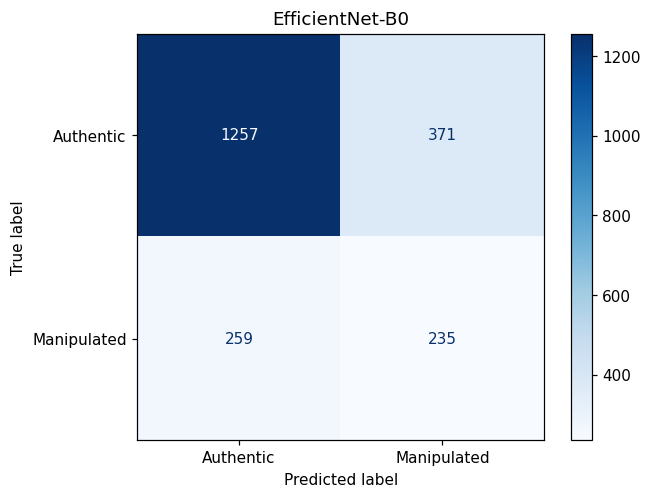

,precision,recall,f1-score,support
Authentic,0.829156,0.772113,0.799618,1628.00000
Manipulated,0.387789,0.475709,0.427273,494.00000
accuracy,0.703110,0.703110,0.703110,0.70311
macro avg,0.608472,0.623911,0.613446,2122.00000
weighted avg,0.726406,0.703110,0.712937,2122.00000


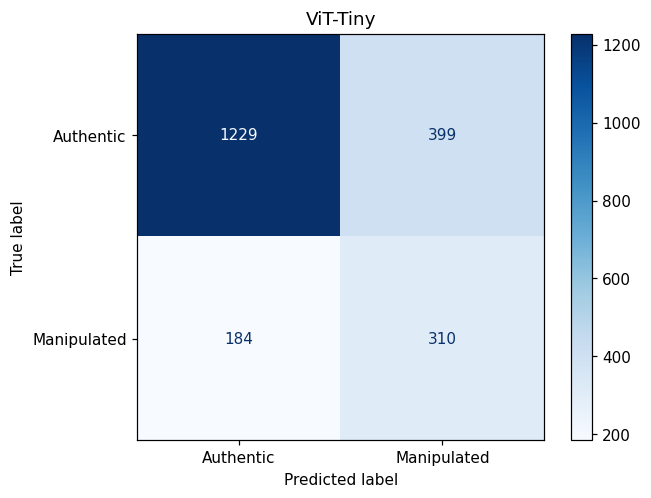

,precision,recall,f1-score,support
Authentic,0.869781,0.754914,0.808287,1628.000000
Manipulated,0.437236,0.627530,0.515378,494.000000
accuracy,0.725259,0.725259,0.725259,0.725259
macro avg,0.653508,0.691222,0.661832,2122.000000
weighted avg,0.769084,0.725259,0.740098,2122.000000


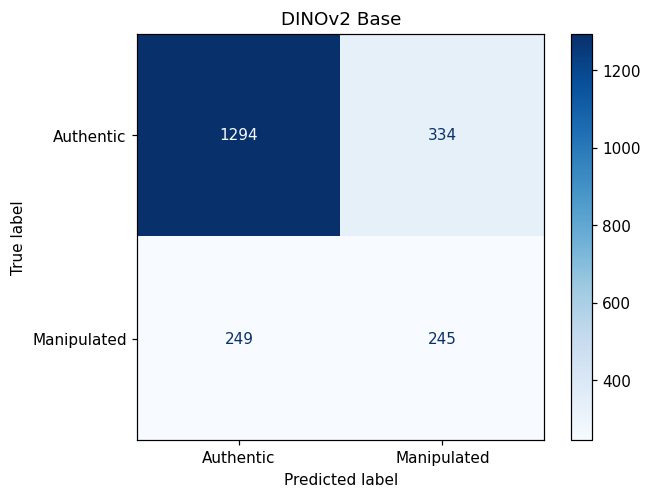

,precision,recall,f1-score,support
Authentic,0.838626,0.794840,0.816146,1628.000000
Manipulated,0.423143,0.495951,0.456664,494.000000
accuracy,0.725259,0.725259,0.725259,0.725259
macro avg,0.630885,0.645396,0.636405,2122.000000
weighted avg,0.741902,0.725259,0.732459,2122.000000


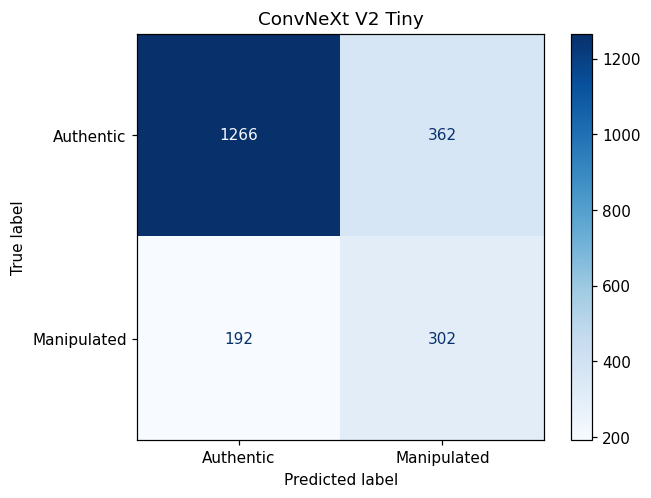

,precision,recall,f1-score,support
Authentic,0.868313,0.777641,0.820480,1628.000000
Manipulated,0.454819,0.611336,0.521589,494.000000
accuracy,0.738926,0.738926,0.738926,0.738926
macro avg,0.661566,0.694489,0.671034,2122.000000
weighted avg,0.772052,0.738926,0.750898,2122.000000


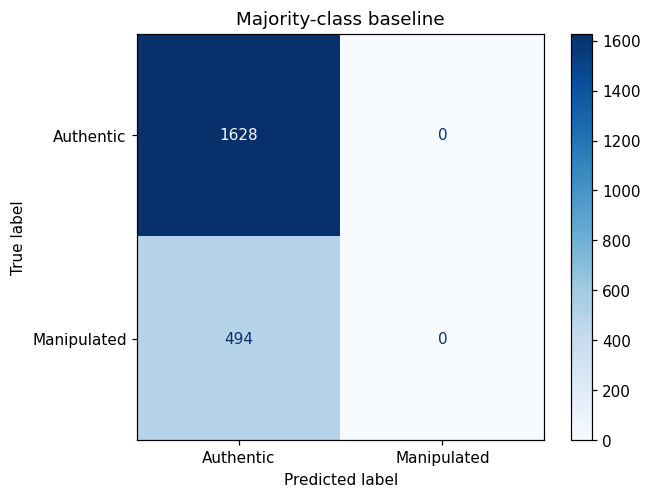

,precision,recall,f1-score,support
Authentic,0.767201,1.000000,0.868267,1628.000000
Manipulated,0.000000,0.000000,0.000000,494.000000
accuracy,0.767201,0.767201,0.767201,0.767201
macro avg,0.383600,0.500000,0.434133,2122.000000
weighted avg,0.588597,0.767201,0.666135,2122.000000


In [5]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

results = {model["display_name"]: model["test"] for model in metrics["models"].values()}
results["Majority-class baseline"] = metrics["majority_baseline_test"]
display(pd.DataFrame({
    name: {"Accuracy": result["accuracy"], "Macro F1": result["macro_f1"],
           "JPEG-only macro F1": result.get("jpeg_only", {}).get("macro_f1"),
           "Manipulated precision": result["classification_report"]["Manipulated"]["precision"],
           "Manipulated recall": result["classification_report"]["Manipulated"]["recall"]}
    for name, result in results.items()
}).T)
print("Selected by validation macro F1:", metrics["selected_by_validation"])
for name, result in results.items():
    ConfusionMatrixDisplay(np.asarray(result["confusion_matrix"]),
                           display_labels=["Authentic", "Manipulated"]).plot(cmap="Blues")
    plt.title(name)
    plt.show()
    display(pd.DataFrame(result["classification_report"]).T)

### Check for a dataset shortcut
The dataset contains different proportions of JPG, BMP and TIFF by class. The encoders see decoded pixel arrays, so the archive filename is never a feature, but encoding differences may leave visual traces. Inspect the held-out format breakdown before interpreting the benchmark.

In [6]:
manifest = pd.read_csv(OUT / "split.csv")
test = manifest.loc[manifest["split"] == "test"].copy()
test["extension"] = test["path"].map(lambda path: Path(path).suffix.lower())
display(pd.crosstab(test["extension"], test["label"].map({0: "Authentic", 1: "Manipulated"})))

label,Authentic,Manipulated
extension,,
.bmp,2,0
.jpg,1626,111
.tif,0,383


### Try held-out images
Set DATA to the extracted dataset root to call the same prediction function as the Gradio app. The cell tries one held-out example from each class. Training and validation images are excluded from this demo. For the live presentation, use the test_predictions.csv file to also select an example where the models disagree or both misclassify it.

In [7]:
if DATA is not None:
    from PIL import Image
    from app import analyze

    for label, examples in test[test["extension"].eq(".jpg")].groupby("label"):
        path = DATA / examples.iloc[0]["path"]
        with Image.open(path) as sample:
            output = analyze(sample)
        print(f"Actual label: {['Authentic', 'Manipulated'][label]} | {path.name}")
        print("Validation-selected model:", output)
else:
    print("Set DATA to the extracted CASIA dataset to try held-out images.")

Set DATA to the extracted CASIA dataset to try held-out images.


## 6. Results and deployment

| Model | Validation macro F1 | Test accuracy | Test macro F1 | Manipulated recall | JPEG-only macro F1 |
|---|---:|---:|---:|---:|---:|
| EfficientNet-B0 | 0.615 | 70.31% | 0.613 | 47.6% | 0.528 |
| ViT-Tiny | 0.667 | 72.53% | 0.662 | 62.8% | 0.528 |
| DINOv2 Base | 0.654 | 72.53% | 0.636 | 49.6% | 0.541 |
| ConvNeXt V2 Tiny | 0.681 | 73.89% | 0.671 | 61.1% | 0.557 |
| Majority class | — | 76.72% | 0.434 | 0.0% | — |

The same split included 8,370 training, 2,122 validation and 2,122 test images. Validation macro F1 selected **ConvNeXt V2 Tiny**. Its test macro F1 was 0.671 compared with 0.662 for ViT-Tiny. It detected 302 of 494 manipulated images, including 68 of 111 manipulated JPEGs. The majority baseline predicted Authentic for every image.

The models can exploit dataset-specific visual patterns. Compare the overall and JPEG-only results, and interpret the confusion matrices before using either model on photos from other sources. For a local demo, run `python app.py` from the extracted project. Once deployed to Hugging Face Spaces, verify a real upload and paste the live URL into the first cell.

In [ ]:
from shutil import make_archive
print(make_archive("PixelDetective-artifacts", "zip", root_dir=".", base_dir="artifacts"))

### Optional deployment from Colab
After authenticating with your own Hugging Face account, set the owner and Space name below. Run this cell only when you are ready to create a public Space. A public Space exposes the app, code, evaluation summary and trained heads. This uploads only the files listed below. The target must be a new project Space or a Space you own and intend to update.

In [9]:
# Set to an owner/Space repository ID before running, e.g. "my-account/pixeldetective".
SPACE_ID = ""
if SPACE_ID:
    from huggingface_hub import HfApi, CommitOperationAdd, notebook_login

    from modeling import MODELS

    paths = ["README.md", "app.py", "modeling.py", "requirements.txt",
             "artifacts/metrics.json"]
    paths.extend(f"artifacts/{key}_head.json" for key in MODELS)
    assert all(Path(path).is_file() for path in paths), "Run evaluation first."
    notebook_login()
    api = HfApi()
    api.create_repo(SPACE_ID, repo_type="space", space_sdk="gradio", private=False, exist_ok=True)
    api.create_commit(
        repo_id=SPACE_ID, repo_type="space", commit_message="Publish PixelDetective",
        operations=[CommitOperationAdd(path_in_repo=path, path_or_fileobj=path) for path in paths],
    )
    print(f"https://huggingface.co/spaces/{SPACE_ID}")

## Instructor reference task
Open both [emotion prediction notebooks](https://github.com/haqnawaz99/ml-teaching-notebooks) in Colab with their corresponding CSVs. Review training-only TF-IDF, six base classifier families, the binary notebook's class-weighting comparison, and the different F1 definitions used to rank predictions.

Local run using the supplied reference CSVs: balanced decision tree, 0.8146 Joy F1 (binary); Linear SVM, 0.7805 macro F1 (six classes). Repeat the runs in Colab as requested in Task 1.